In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.append('..')
from datasets.super_res_dataset_fourier import SuperResDataset

In [5]:
# 1. Initialize the dataset objects using your files
hr_files = ['../data/100/window_2003.npy']
sigma = 10

# Instance without filter to capture the unfiltered coarse spectrum
dataset_coarse = SuperResDataset(hr_files=hr_files, downsample_factor=4, freq_threshold=None)
# Instance with filter to get the final low-resolution output
dataset_filtered = SuperResDataset(hr_files=hr_files, downsample_factor=4, freq_threshold=sigma)

# Pull sample 0 from both configurations
lr_coarse, hr_tensor = dataset_coarse[0]
lr_tensor_final, _ = dataset_filtered[0]

(1000, 128, 128, 6)
(1000, 128, 128, 6)


In [24]:
C, H, W = lr_coarse.shape
cy, cx = H // 2, W // 2

# Recreate the Gaussian mask matching your dataset's inner logic
y_grid, x_grid = torch.meshgrid(torch.arange(H), torch.arange(W), indexing='ij')
dist_sq = (x_grid - cx)**2 + (y_grid - cy)**2
gaussian_mask = torch.exp(-dist_sq / (2 * (sigma**2)))

spectra_unfiltered = []
spectra_filtered = []

for c in range(C):
    # Unfiltered spectrum calculations
    freq_domain = torch.fft.fft2(lr_coarse[c])
    freq_shifted = torch.fft.fftshift(freq_domain)
    mag_unfiltered = torch.log(torch.abs(freq_shifted) + 1)
    spectra_unfiltered.append(mag_unfiltered.numpy())
    
    # Filtered spectrum calculations (multiplying by the Gaussian mask)
    freq_shifted_filtered = freq_shifted * gaussian_mask
    mag_filtered = torch.log(torch.abs(freq_shifted_filtered) + 1)
    spectra_filtered.append(mag_filtered.numpy())

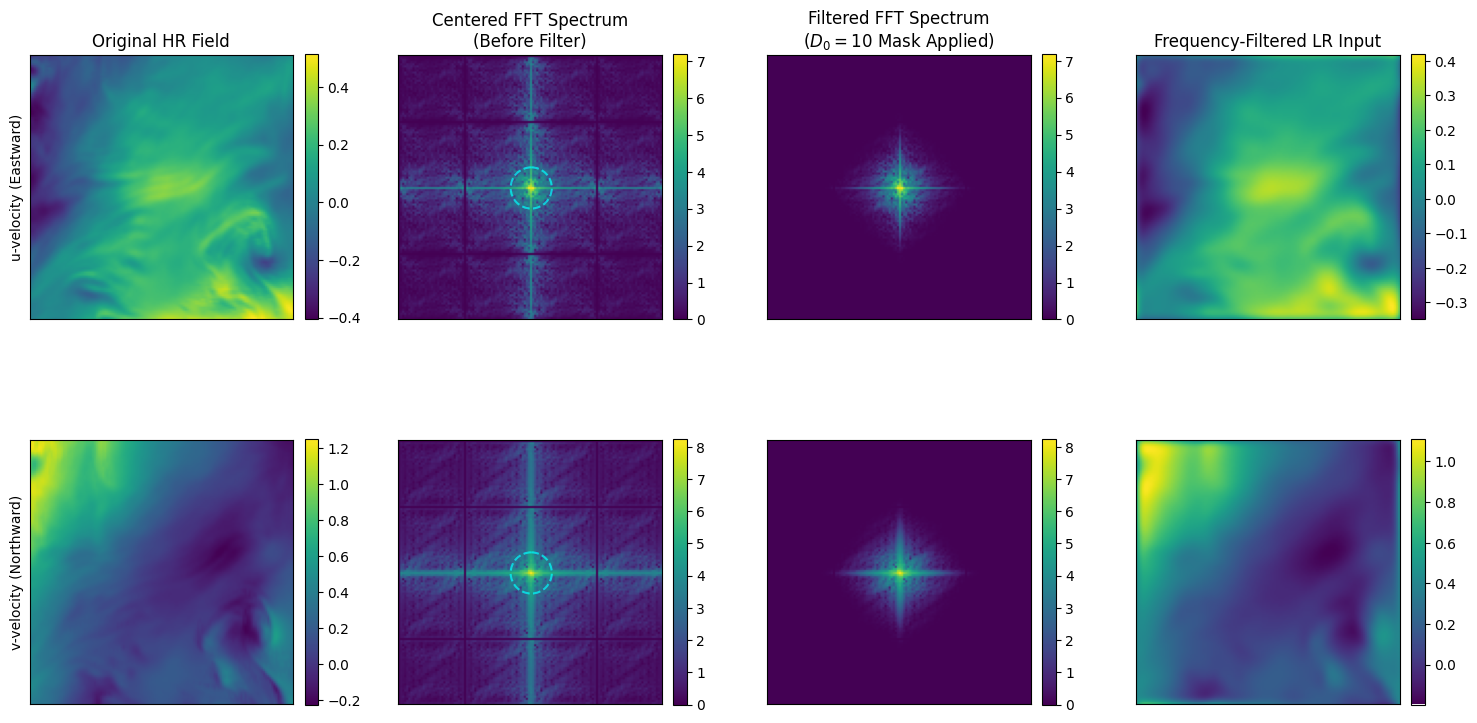

In [25]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
plt.subplots_adjust(wspace=0.28, hspace=0.25)
   
titles = [
    "Original HR Field", 
    "Centered FFT Spectrum\n(Before Filter)", 
    f"Filtered FFT Spectrum\n($D_0={sigma}$ Mask Applied)", 
    "Frequency-Filtered LR Input"
]
variables = ["u-velocity (Eastward)", "v-velocity (Northward)"]

for row, var_name in enumerate(variables):
    # Column 1: High-Resolution Ground Truth
    im0 = axes[row, 0].imshow(hr_tensor[row].numpy())
    axes[row, 0].set_ylabel(var_name)
    fig.colorbar(im0, ax=axes[row, 0], fraction=0.046, pad=0.04)
    
    # Column 2: Centered Frequency Spectrum (Unfiltered)
    im1 = axes[row, 1].imshow(spectra_unfiltered[row])
    # Overlay a subtle dashed circle indicating the mask boundary
    circle = plt.Circle((cx, cy), sigma, color='cyan', fill=False, linestyle='--', linewidth=1.5, alpha=0.7)
    axes[row, 1].add_patch(circle)
    fig.colorbar(im1, ax=axes[row, 1], fraction=0.046, pad=0.04)
    
    # Column 3: Centered Frequency Spectrum (After Gaussian Mask)
    im2 = axes[row, 2].imshow(spectra_filtered[row])
    fig.colorbar(im2, ax=axes[row, 2], fraction=0.046, pad=0.04)
    
    # Column 4: Resulting Frequency-Downsampled low-res input
    im3 = axes[row, 3].imshow(lr_tensor_final[row].numpy())
    fig.colorbar(im3, ax=axes[row, 3], fraction=0.046, pad=0.04)
    
    for col in range(4):
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

for col, title in enumerate(titles):
    axes[0, col].set_title(title)


plt.savefig('downsampling_comparison_spectra.png', bbox_inches='tight', dpi=300)
plt.show()